# Results Visualization

Set `RESULTS_DIR` to the timestamped folder generated by `run_evaluation.py`.

In [7]:
import os
import yaml
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import matplotlib.patheffects as pe

# Set this to your specific results directory
RESULTS_DIR = "results/20260324_193437"

# Auto-detect latest results directory if PENDING
if RESULTS_DIR == "results/PENDING" and os.path.exists("results"):
    subdirs = [os.path.join("results", d) for d in os.listdir("results") if os.path.isdir(os.path.join("results", d))]
    if subdirs:
        RESULTS_DIR = max(subdirs, key=os.path.getmtime)
        print(f"Auto-selected latest results: {RESULTS_DIR}")

# Load configuration
config_path = os.path.join(RESULTS_DIR, "config.yaml")
if os.path.exists(config_path):
    with open(config_path, "r") as f:
        config = yaml.unsafe_load(f)
else:
    print(f"Warning: config.yaml not found in {RESULTS_DIR}")
    config = {}

## 1. Causal Graphs

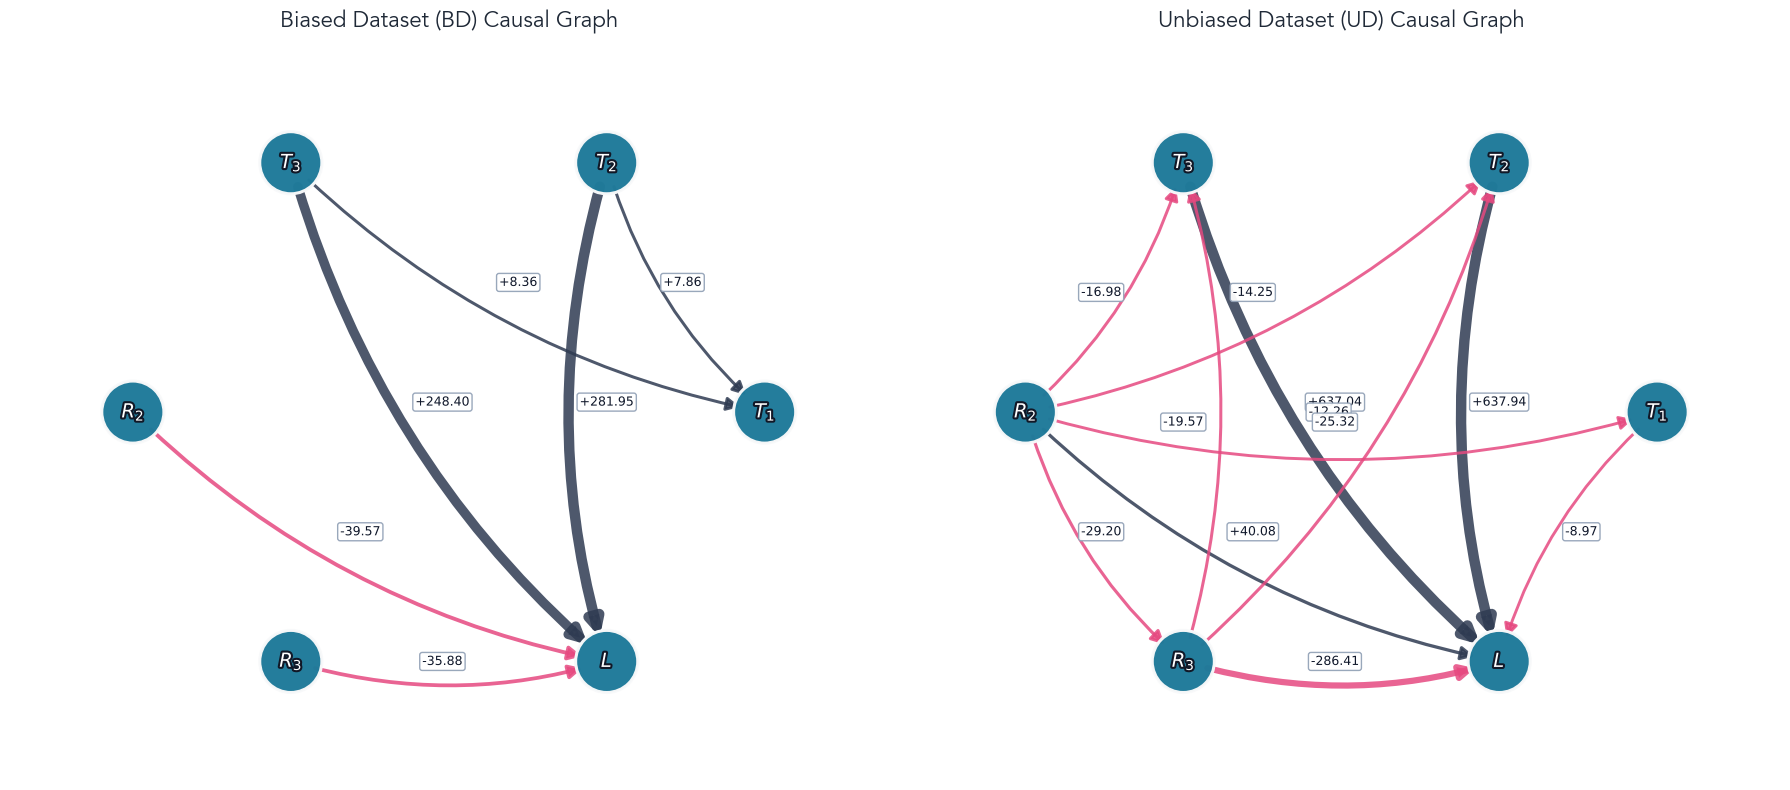

In [8]:
def draw_single_causal_graph(ax, labels, adj_matrix, target_label, title):
    if adj_matrix is None or len(adj_matrix) == 0 or labels is None:
        ax.text(0.5, 0.5, "Graph not available", ha='center', va='center', fontsize=14)
        ax.set_title(title)
        ax.axis("off")
        return

    G = nx.DiGraph()
    for label in labels:
        G.add_node(label)

    edge_candidates = []
    for i in range(len(labels)):
        for j in range(len(labels)):
            weight = float(adj_matrix[i, j])
            if i == j or abs(weight) <= 1e-6:
                continue
            source = labels[j]
            target = labels[i]
            edge_candidates.append((source, target, weight))

    strongest_by_pair = {}
    for source, target, weight in edge_candidates:
        pair_key = tuple(sorted((source, target)))
        prev = strongest_by_pair.get(pair_key)
        if prev is None or abs(weight) > abs(prev[2]):
            strongest_by_pair[pair_key] = (source, target, weight)

    for source, target, weight in strongest_by_pair.values():
        G.add_edge(source, target, weight=weight)

    n_nodes = max(1, len(G.nodes()))
    if n_nodes <= 8:
        pos = nx.circular_layout(G, scale=0.9)
    else:
        pos = nx.spring_layout(G, k=0.55 / np.sqrt(n_nodes), iterations=400, seed=42)

    node_colors = ["#ef5350" if node == target_label else "#1f7a9a" for node in G.nodes()]

    nx.draw_networkx_nodes(
        G, pos, node_color=node_colors, node_size=2000, linewidths=2.2, edgecolors="#f8f9fa", ax=ax, alpha=0.98,
    )

    edges = list(G.edges())
    weights = [abs(G[u][v]["weight"]) for u, v in edges]
    max_weight = max(weights) if weights else 1.0
    edge_widths = [2.0 + 5.5 * (w / max_weight) for w in weights]
    edge_colors = ["#2f3b52" if G[u][v]["weight"] >= 0 else "#e64980" for u, v in edges]

    nx.draw_networkx_edges(
        G, pos, width=edge_widths, edge_color=edge_colors, ax=ax, alpha=0.85,
        arrows=True, arrowsize=20, arrowstyle="-|>", connectionstyle="arc3,rad=0.15",
        min_source_margin=18, min_target_margin=18,
    )

    def format_node_label(node):
        if node == "service_frame_sampler_arrival_rate": return r"$T_{1}$"
        if node == "service_frame_resizer_arrival_rate": return r"$T_{2}$"
        if node == "service_object_detector_arrival_rate": return r"$T_{3}$"
        if node == "service_frame_resizer_replicas": return r"$R_{2}$"
        if node == "service_object_detector_replicas": return r"$R_{3}$"
        if node == "e2e_latency" or node == "service_object_detector_latency": return r"$L$"
        return node.replace("service_object_detector_", "").replace("_", " ")

    label_map = {node: format_node_label(node) for node in G.nodes()}
    
    node_text = nx.draw_networkx_labels(
        G, pos, labels=label_map, font_size=14, font_weight="bold", font_color="#ffffff", ax=ax,
    )
    for txt in node_text.values():
        txt.set_path_effects([pe.withStroke(linewidth=3.0, foreground="#111827")])

    edge_labels = {(u, v): f"{G[u][v]['weight']:+.2f}" for u, v in G.edges()}
    edge_text = nx.draw_networkx_edge_labels(
        G, pos, edge_labels=edge_labels, font_size=9, rotate=False, label_pos=0.52, font_color="#0f172a",
        bbox={"boxstyle": "round,pad=0.2", "fc": "#ffffff", "ec": "#94a3b8", "alpha": 0.95}, ax=ax,
    )
    for txt in edge_text.values():
        txt.set_path_effects([pe.withStroke(linewidth=1.6, foreground="#ffffff")])

    ax.set_title(title, fontsize=16, fontweight="semibold", color="#1f2937", pad=12)
    ax.set_xlim(-1.25, 1.25)
    ax.set_ylim(-1.15, 1.15)
    ax.set_facecolor("#f6f8fb")
    ax.axis("off")

labels_file = os.path.join(RESULTS_DIR, "causal_labels.json")
if os.path.exists(labels_file):
    with open(labels_file, "r") as f:
        causal_data = json.load(f)
    
    bd_adj_file = os.path.join(RESULTS_DIR, "bd_adj.npy")
    ud_adj_file = os.path.join(RESULTS_DIR, "ud_adj.npy")
    
    bd_adj = np.load(bd_adj_file) if os.path.exists(bd_adj_file) else None
    ud_adj = np.load(ud_adj_file) if os.path.exists(ud_adj_file) else None
    
    plt.rcParams["font.family"] = ["Avenir", "Helvetica Neue", "DejaVu Sans"]
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))

    draw_single_causal_graph(axes[0], causal_data["bd_labels"], bd_adj, causal_data["bd_target"], "Biased Dataset (BD) Causal Graph")
    draw_single_causal_graph(axes[1], causal_data["ud_labels"], ud_adj, causal_data["ud_target"], "Unbiased Dataset (UD) Causal Graph")

    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "causal_graphs.pdf"), format="pdf", bbox_inches="tight")
    plt.show()
else:
    print("Causal graphs not found.")

## 2. Training Curves

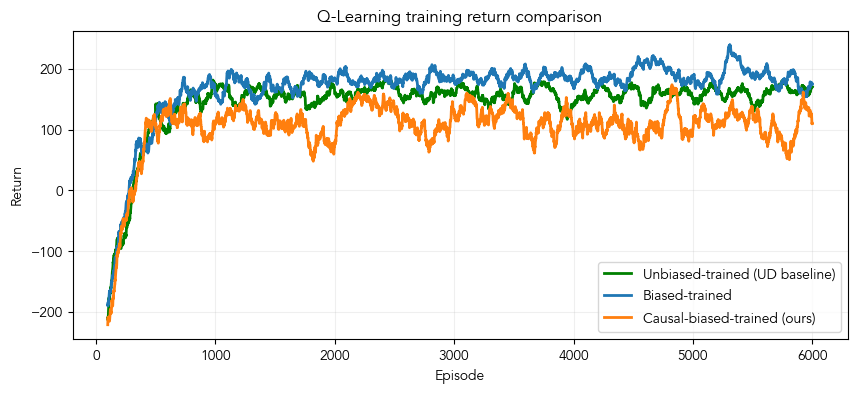

In [9]:
curves_file = os.path.join(RESULTS_DIR, "training_curves.csv")
if os.path.exists(curves_file):
    df_curves = pd.read_csv(curves_file)
    window = 100
    
    plt.figure(figsize=(10, 4))
    
    ret_u = df_curves["unbiased"].to_numpy()
    ma_u = np.convolve(ret_u, np.ones(window)/window, mode="valid")
    plt.plot(np.arange(window-1, len(ret_u)), ma_u, linewidth=2.0, label="Unbiased-trained (UD baseline)", color="green")
    
    ret_b = df_curves["biased"].to_numpy()
    ma_b = np.convolve(ret_b, np.ones(window)/window, mode="valid")
    plt.plot(np.arange(window-1, len(ret_b)), ma_b, linewidth=2.0, label="Biased-trained", color="#1f77b4")
    
    ret_c = df_curves["causal_biased"].to_numpy()
    ma_c = np.convolve(ret_c, np.ones(window)/window, mode="valid")
    plt.plot(np.arange(window-1, len(ret_c)), ma_c, linewidth=2.0, label="Causal-biased-trained (ours)", color="#ff7f0e")

    plt.title("Q-Learning training return comparison")
    plt.xlabel("Episode")
    plt.ylabel("Return")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.savefig(os.path.join(RESULTS_DIR, "training_curves.pdf"), format="pdf", bbox_inches="tight")
    plt.show()
else:
    print("Training curves not found.")

## 3. Progressive RD Experiment

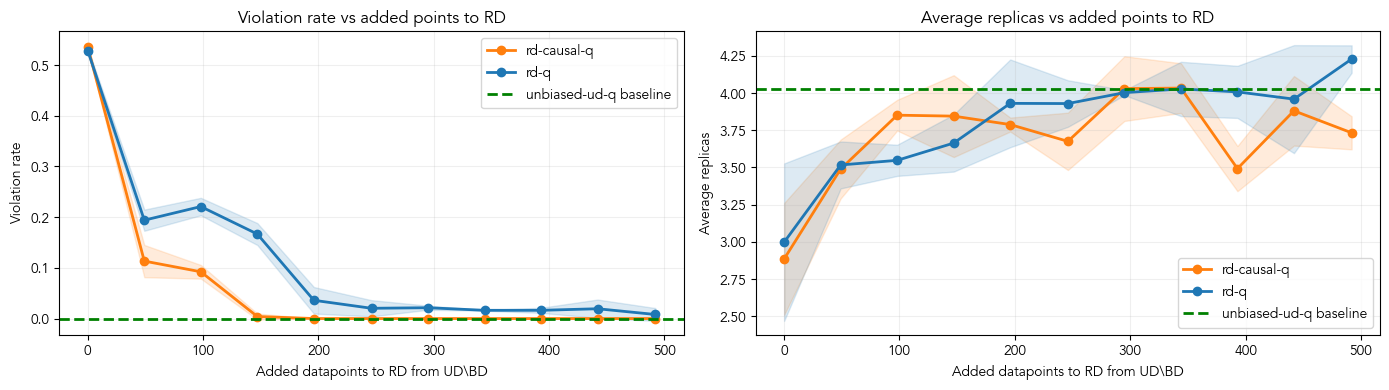

In [10]:
rd_summary_file = os.path.join(RESULTS_DIR, "rd_summary.csv")
rd_baselines_file = os.path.join(RESULTS_DIR, "rd_baselines.json")

if os.path.exists(rd_summary_file) and os.path.exists(rd_baselines_file):
    rd_summary = pd.read_csv(rd_summary_file)
    with open(rd_baselines_file, "r") as f:
        baselines = json.load(f)
        
    unbiased_violation_baseline = baselines["unbiased_violation_baseline"]
    unbiased_replicas_baseline = baselines["unbiased_replicas_baseline"]

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    colors_rd = {"unbiased-ud-q baseline": "green", "rd-q": "#1f77b4", "rd-causal-q": "#ff7f0e"}
    
    for agent_name, g in rd_summary.groupby("agent"):
        g = g.sort_values("added_points")
        x = g["added_points"].to_numpy(dtype=float)

        y_v = g["violation_rate_mean"].to_numpy(dtype=float)
        s_v = np.nan_to_num(g["violation_rate_std"].to_numpy(dtype=float), nan=0.0)
        axes[0].plot(x, y_v, marker="o", linewidth=2, label=agent_name, color=colors_rd.get(agent_name, None))
        axes[0].fill_between(x, y_v - s_v, y_v + s_v, alpha=0.15, color=colors_rd.get(agent_name, None))

        y_r = g["avg_replicas_mean"].to_numpy(dtype=float)
        s_r = np.nan_to_num(g["avg_replicas_std"].to_numpy(dtype=float), nan=0.0)
        axes[1].plot(x, y_r, marker="o", linewidth=2, label=agent_name, color=colors_rd.get(agent_name, None))
        axes[1].fill_between(x, y_r - s_r, y_r + s_r, alpha=0.15, color=colors_rd.get(agent_name, None))

    axes[0].axhline(unbiased_violation_baseline, linestyle="--", linewidth=2, color="green", label="unbiased-ud-q baseline")
    axes[1].axhline(unbiased_replicas_baseline, linestyle="--", linewidth=2, color="green", label="unbiased-ud-q baseline")

    axes[0].set_title("Violation rate vs added points to RD")
    axes[0].set_xlabel(r"Added datapoints to RD from UD\BD")
    axes[0].set_ylabel("Violation rate")
    axes[0].grid(alpha=0.2)
    axes[0].legend()

    axes[1].set_title("Average replicas vs added points to RD")
    axes[1].set_xlabel(r"Added datapoints to RD from UD\BD")
    axes[1].set_ylabel("Average replicas")
    axes[1].grid(alpha=0.2)
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "rd_experiment.pdf"), format="pdf", bbox_inches="tight")
    plt.show()
else:
    print("RD summary or baselines not found.")

## 3.1 RD Experiment T1 vs Replicas

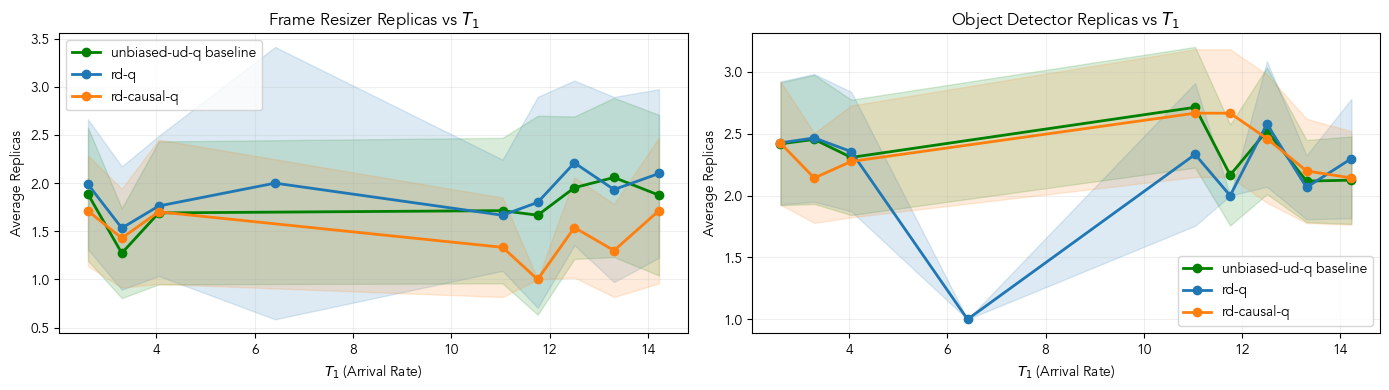

In [11]:
rd_t1_file = os.path.join(RESULTS_DIR, "rd_t1_replicas.csv")

if os.path.exists(rd_t1_file):
    df_t1 = pd.read_csv(rd_t1_file)
    action_cols = [c for c in df_t1.columns if c not in ["agent", "repeat", "t1"]]
    
    colors_t1 = {
        "unbiased-ud-q baseline": "green", 
        "rd-q": "#1f77b4", 
        "rd-causal-q": "#ff7f0e"
    }
    
    # Create bins for t1 to smooth the visualization
    n_bins = 15
    df_t1['t1_bins'] = pd.cut(df_t1['t1'], bins=n_bins, labels=False)
    # Map back to the center of the bin for plotting
    bin_centers = df_t1.groupby('t1_bins')['t1'].mean()
    df_t1['t1_center'] = df_t1['t1_bins'].map(bin_centers)
    
    fig, axes = plt.subplots(1, len(action_cols), figsize=(7 * len(action_cols), 4))
    if len(action_cols) == 1:
        axes = [axes]
        
    for agent_name in df_t1["agent"].unique():
        color = colors_t1.get(agent_name, None)
        df_agent = df_t1[df_t1["agent"] == agent_name]
        
        for i, col in enumerate(action_cols):
            # Group by the binned t1
            grouped = df_agent.groupby("t1_center")[col].agg(["mean", "std"]).reset_index()
            grouped = grouped.sort_values("t1_center")
            
            x = grouped["t1_center"].to_numpy()
            y = grouped["mean"].to_numpy()
            y_std = grouped["std"].fillna(0).to_numpy()
            
            axes[i].plot(x, y, marker="o", linewidth=2, label=agent_name, color=color)
            axes[i].fill_between(x, y - y_std, y + y_std, alpha=0.15, color=color)
            
    for i, col in enumerate(action_cols):
        nice_name = col.replace("service_", "").replace("_", " ").title()
        axes[i].set_title(f"{nice_name} vs $T_1$")
        axes[i].set_xlabel(r"$T_1$ (Arrival Rate)")
        axes[i].set_ylabel("Average Replicas")
        axes[i].grid(alpha=0.2)
        axes[i].legend()
        
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "rd_t1_replicas.pdf"), format="pdf", bbox_inches="tight")
    plt.show()
else:
    print("RD T1 replicas file not found.")

## 4. Threshold Experiment

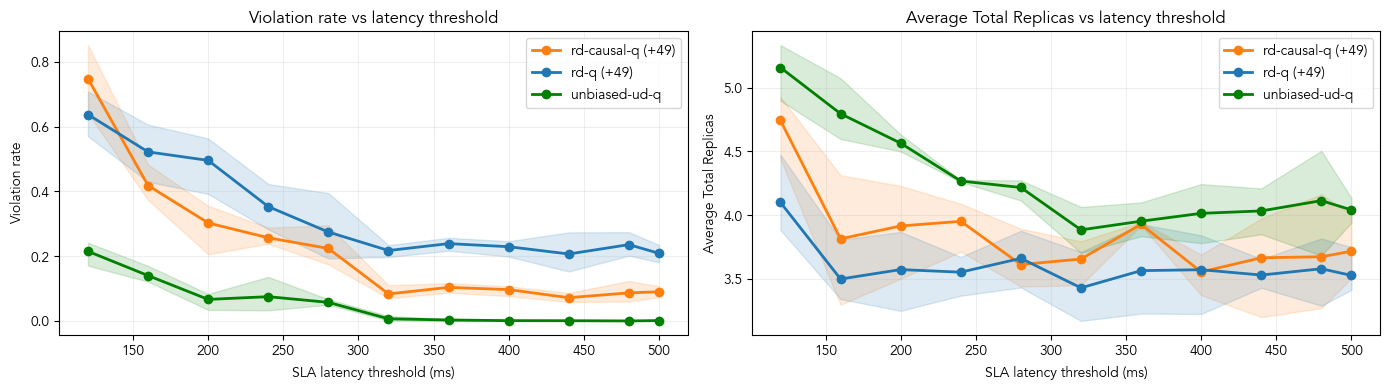

In [12]:
threshold_summary_file = os.path.join(RESULTS_DIR, "threshold_summary.csv")

if os.path.exists(threshold_summary_file):
    rd60_summary = pd.read_csv(threshold_summary_file)
    n_add = "Fixed Amount" # Will read from descriptive text in names generally
    # Try to extract the number of added points directly from one of the labels
    for model_name in rd60_summary["model"].unique():
        if "rd-q" in model_name:
            n_add = model_name
            break

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    colors_sla = {
        "unbiased-ud-q": "green", 
        "rd-q": "#1f77b4", 
        "rd-causal-q": "#ff7f0e"
    }

    # Match color carefully even when label contains (+N) strings
    def get_color(m):
        for k, v in colors_sla.items():
            if m.startswith(k): return v
        return None

    for model_name, g in rd60_summary.groupby("model"):
        g = g.sort_values("sla_latency_ms")
        x = g["sla_latency_ms"].to_numpy(dtype=float)
        
        y_v = g["violation_rate_mean"].to_numpy(dtype=float)
        y_v_min = g["violation_rate_min"].to_numpy(dtype=float)
        y_v_max = g["violation_rate_max"].to_numpy(dtype=float)
        axes[0].plot(x, y_v, marker="o", linewidth=2, label=model_name, color=get_color(model_name))
        axes[0].fill_between(x, y_v_min, y_v_max, alpha=0.15, color=get_color(model_name))
        
        y_r = g["avg_replicas_mean"].to_numpy(dtype=float)
        y_r_min = g["avg_replicas_min"].to_numpy(dtype=float)
        y_r_max = g["avg_replicas_max"].to_numpy(dtype=float)
        axes[1].plot(x, y_r, marker="o", linewidth=2, label=model_name, color=get_color(model_name))
        axes[1].fill_between(x, y_r_min, y_r_max, alpha=0.15, color=get_color(model_name))

    axes[0].set_title("Violation rate vs latency threshold")
    axes[0].set_xlabel("SLA latency threshold (ms)")
    axes[0].set_ylabel("Violation rate")
    axes[0].grid(alpha=0.2)
    axes[0].legend()

    axes[1].set_title("Average Total Replicas vs latency threshold")
    axes[1].set_xlabel("SLA latency threshold (ms)")
    axes[1].set_ylabel("Average Total Replicas")
    axes[1].grid(alpha=0.2)
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "threshold_experiment.pdf"), format="pdf", bbox_inches="tight")
    plt.show()
else:
    print("Threshold summary not found.")